#D3 Deliverable: Clean Data, Exploratory Data Analysis & Hypothesis Testing

##Data Inspection

In [0]:
%pip install seaborn
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

Looking in indexes: [REDACTED]
Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


In [0]:
df = pd.read_csv("/Volumes/bap_project/bap_project_db/project_db/shopping_trends.csv")

In [0]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3900 entries, 0 to 3899
Data columns (total 19 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Customer ID               3900 non-null   int64  
 1   Age                       3900 non-null   int64  
 2   Gender                    3900 non-null   object 
 3   Item Purchased            3900 non-null   object 
 4   Category                  3900 non-null   object 
 5   Purchase Amount (USD)     3900 non-null   int64  
 6   Location                  3900 non-null   object 
 7   Size                      3900 non-null   object 
 8   Color                     3900 non-null   object 
 9   Season                    3900 non-null   object 
 10  Review Rating             3900 non-null   float64
 11  Subscription Status       3900 non-null   object 
 12  Payment Method            3900 non-null   object 
 13  Shipping Type             3900 non-null   object 
 14  Discount

In [0]:
df.shape

(3900, 19)

In [0]:
df.describe()

,Customer ID,Age,Purchase Amount (USD),Review Rating,Previous Purchases
count,3900.000000,3900.000000,3900.000000,3900.000000,3900.000000
mean,1950.500000,44.068462,59.764359,3.749949,25.351538
std,1125.977353,15.207589,23.685392,0.716223,14.447125
min,1.000000,18.000000,20.000000,2.500000,1.000000
25%,975.750000,31.000000,39.000000,3.100000,13.000000
50%,1950.500000,44.000000,60.000000,3.700000,25.000000
75%,2925.250000,57.000000,81.000000,4.400000,38.000000
max,3900.000000,70.000000,100.000000,5.000000,50.000000


##Data Cleaning Log

In [0]:

# 1. Initial shape & inspection
print(f"Initial Dataset Shape: {df.shape}")

# 2. Cleaning Log Initialization
cleaning_log = []

# Check missing values
missing_vals = df.isnull().sum().sum()
cleaning_log.append(f"Checked missing values: Found {missing_vals} missing entries.")

# Check duplicates
duplicates = df.duplicated().sum()
if duplicates > 0:
    df = df.drop_duplicates()
    cleaning_log.append(f"Removed {duplicates} duplicate rows.")
else:
    cleaning_log.append("Checked duplicates: No duplicate rows found.")

# Standardise column names (snake_case convention)
original_cols = df.columns.tolist()
df.columns = df.columns.str.strip().str.lower().str.replace(' ', '_').str.replace('(', '').str.replace(')', '')
cleaning_log.append(f"Standardised column names from {original_cols} to {df.columns.tolist()}.")

# Strip whitespace from string/object columns
object_cols = df.select_dtypes(include=['object']).columns
for col in object_cols:
    df[col] = df[col].astype(str).str.strip()
cleaning_log.append(f"Stripped leading/trailing whitespaces across {len(object_cols)} categorical columns.")

# Print Cleaning Log Summary
print("\n--- DATA CLEANING LOG ---")
for log in cleaning_log:
    print(f"[CLEANED] {log}")
print(f"Final Dataset Shape: {df.shape}")

Initial Dataset Shape: (3900, 19)

--- DATA CLEANING LOG ---
[CLEANED] Checked missing values: Found 0 missing entries.
[CLEANED] Checked duplicates: No duplicate rows found.
[CLEANED] Standardised column names from ['Customer ID', 'Age', 'Gender', 'Item Purchased', 'Category', 'Purchase Amount (USD)', 'Location', 'Size', 'Color', 'Season', 'Review Rating', 'Subscription Status', 'Payment Method', 'Shipping Type', 'Discount Applied', 'Promo Code Used', 'Previous Purchases', 'Preferred Payment Method', 'Frequency of Purchases'] to ['customer_id', 'age', 'gender', 'item_purchased', 'category', 'purchase_amount_usd', 'location', 'size', 'color', 'season', 'review_rating', 'subscription_status', 'payment_method', 'shipping_type', 'discount_applied', 'promo_code_used', 'previous_purchases', 'preferred_payment_method', 'frequency_of_purchases'].
[CLEANED] Stripped leading/trailing whitespaces across 14 categorical columns.
Final Dataset Shape: (3900, 19)


##Exploratory Data Analysis (EDA) — Charts

In [0]:
# Set visual style
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

###Chart 1: Distribution of Purchase Amounts (USD)

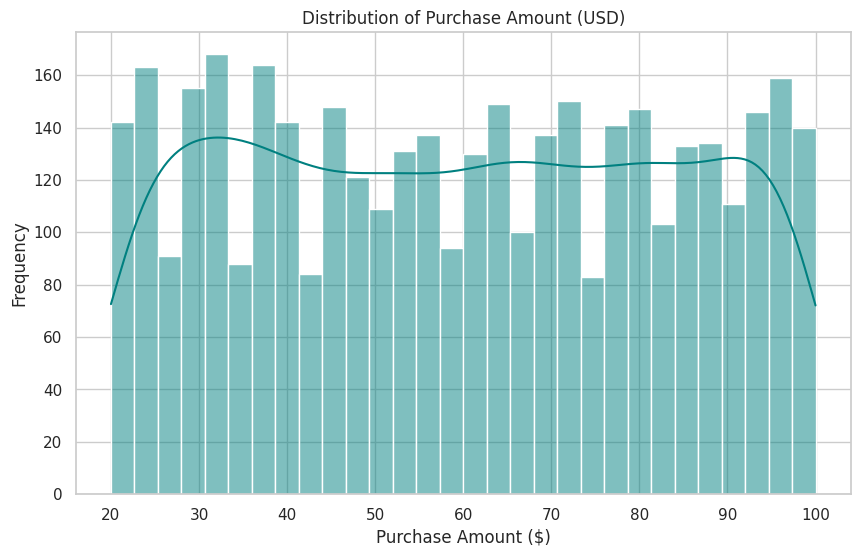

In [0]:
plt.figure()
sns.histplot(df['purchase_amount_usd'], kde=True, color='teal', bins=30)
plt.title('Distribution of Purchase Amount (USD)')
plt.xlabel('Purchase Amount ($)')
plt.ylabel('Frequency')
plt.show()

Insight: Shows whether spending follows a normal distribution or is skewed, helping identify typical transaction sizes.



###Chart 2: Purchase Amount by Product Category

/home/spark-a192f4d8-e74d-4713-abfe-52/.ipykernel/63/command-6360326913092274-204001600:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='category', y='purchase_amount_usd', data=df, palette='Set2')


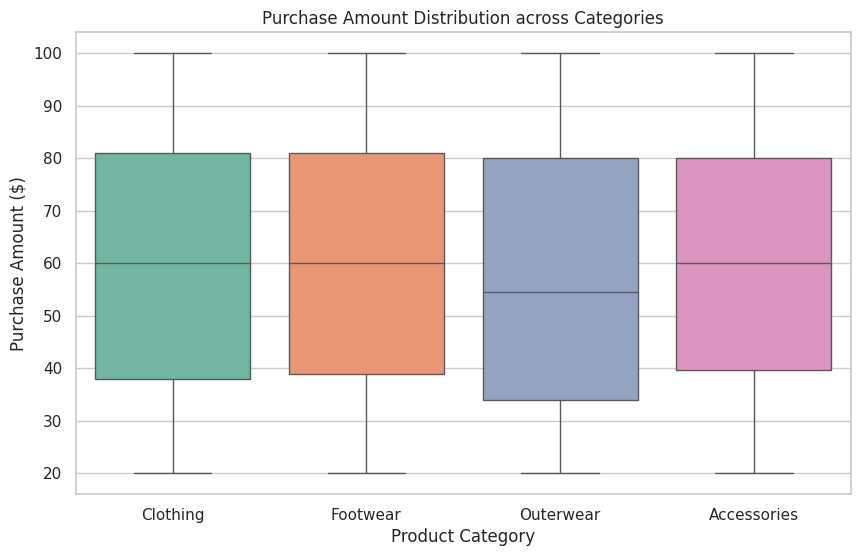

In [0]:
plt.figure()
sns.boxplot(x='category', y='purchase_amount_usd', data=df, palette='Set2')
plt.title('Purchase Amount Distribution across Categories')
plt.xlabel('Product Category')
plt.ylabel('Purchase Amount ($)')
plt.show()

Insight: Compares median and spread of spending across categories (Clothing, Footwear, Outerwear, Accessories).

###Chart 3: Customer Age Distribution by Subscription Status


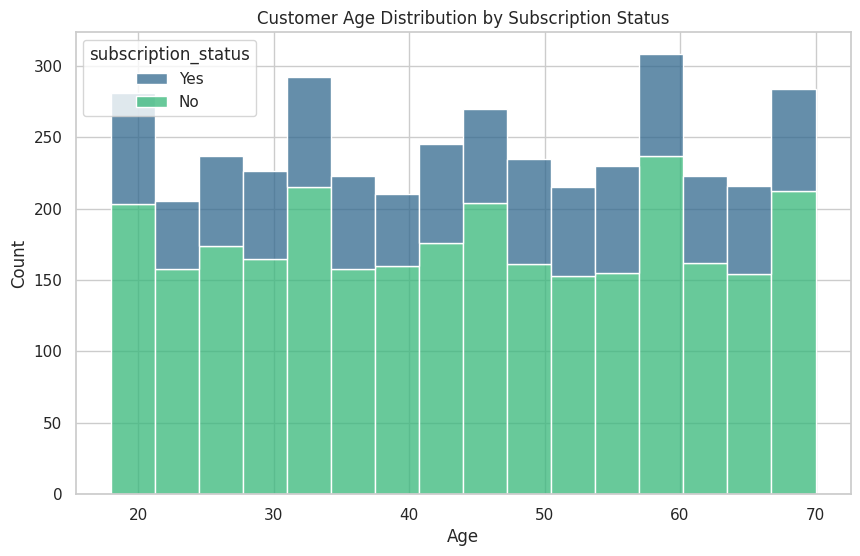

In [0]:
plt.figure()
sns.histplot(data=df, x='age', hue='subscription_status', multiple='stack', palette='viridis')
plt.title('Customer Age Distribution by Subscription Status')
plt.xlabel('Age')
plt.ylabel('Count')
plt.show()

Insight: Identifies which age demographics are actively subscribing to the service.


###Chart 4: Review Ratings by Shipping Type

/home/spark-a192f4d8-e74d-4713-abfe-52/.ipykernel/63/command-6360326913092281-1314119165:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='shipping_type', y='review_rating', data=df, estimator=np.mean, palette='muted')


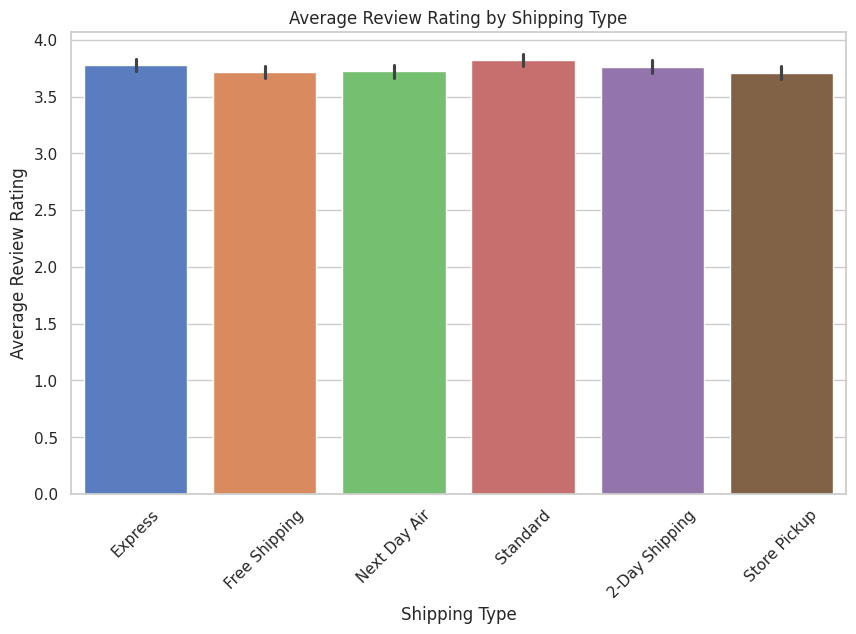

In [0]:
plt.figure()
sns.barplot(x='shipping_type', y='review_rating', data=df, estimator=np.mean, palette='muted')
plt.title('Average Review Rating by Shipping Type')
plt.xlabel('Shipping Type')
plt.ylabel('Average Review Rating')
plt.xticks(rotation=45)
plt.show()

Insight: Evaluates if faster shipping types (e.g., Express, Next Day Air) correlate with higher customer satisfaction ratings.


###Chart 5: Proportion of Purchases by Season and Gender

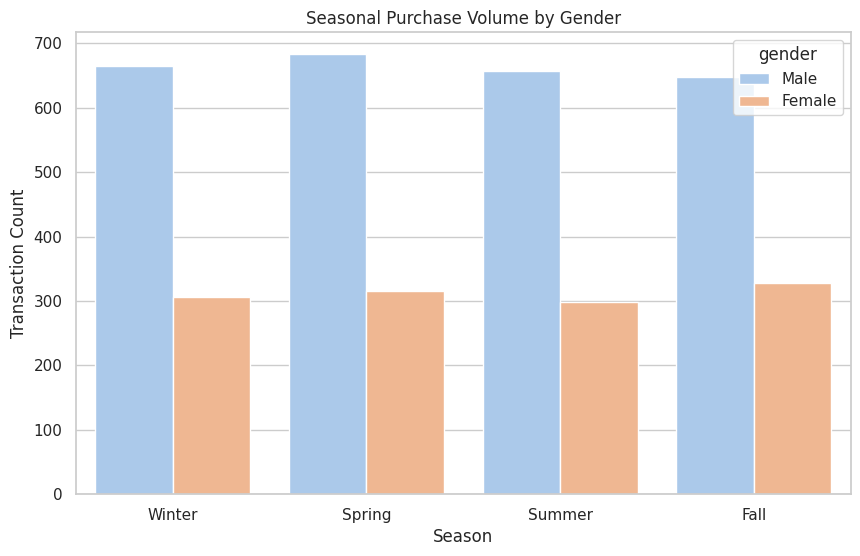

In [0]:
plt.figure()
sns.countplot(data=df, x='season', hue='gender', palette='pastel')
plt.title('Seasonal Purchase Volume by Gender')
plt.xlabel('Season')
plt.ylabel('Transaction Count')
plt.show()

Insight: Highlights seasonal purchasing peaks and gender-based participation trends across seasons.


##Statistical Tests

### Independent Samples t-Test

In [0]:
from scipy import stats
sub_yes = df[df['subscription_status'] == 'Yes']['purchase_amount_usd']
sub_no = df[df['subscription_status'] == 'No']['purchase_amount_usd']

t_stat, p_val = stats.ttest_ind(sub_yes, sub_no)
print(f"t-statistic: {t_stat:.4f}, p-value: {p_val:.4f}")

t-statistic: -0.4368, p-value: 0.6623


Result: The t-statistic is approximately -0.437 with a p-value of 0.662 (which is greater than the standard significance threshold 0.05).

Explanation: There is no statistically significant difference in average spending between customers who have a subscription and those who do not. Both groups spend roughly $59.50 on average per purchase. Therefore, having a subscription does not automatically drive higher cart values; marketing teams should look beyond basket size when evaluating subscription value.
